# Import Libraries

In [1]:
import pandas as pd
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder
from sklearn.impute import SimpleImputer
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

import joblib

# Load the Dataset

In [2]:
df = pd.read_csv("movies_data.csv")

In [3]:
print(df.head())

                                 Name  Year  Duration  \
0  #Gadhvi (He thought he was Gandhi)  2019       109   
1                             #Yaaram  2019       110   
2                ...Aur Pyaar Ho Gaya  1997       147   
3                           ...Yahaan  2005       142   
4                  ?: A Question Mark  2012        82   

                       Genre  Rating  Votes        Director          Actor 1  \
0                      Drama     7.0      8   Gaurav Bakshi     Rasika Dugal   
1            Comedy, Romance     4.4     35      Ovais Khan          Prateik   
2     Comedy, Drama, Musical     4.7    827    Rahul Rawail       Bobby Deol   
3        Drama, Romance, War     7.4   1086  Shoojit Sircar  Jimmy Sheirgill   
4  Horror, Mystery, Thriller     5.6    326   Allyson Patel        Yash Dave   

                  Actor 2          Actor 3  
0          Vivek Ghamande    Arvind Jangid  
1              Ishita Raj  Siddhant Kapoor  
2  Aishwarya Rai Bachchan    Shammi Kapoo

In [4]:
print(df.shape)

(5659, 10)


In [5]:
print(df.columns)

Index(['Name', 'Year', 'Duration', 'Genre', 'Rating', 'Votes', 'Director',
       'Actor 1', 'Actor 2', 'Actor 3'],
      dtype='str')


In [6]:
print(df.info())

<class 'pandas.DataFrame'>
RangeIndex: 5659 entries, 0 to 5658
Data columns (total 10 columns):
 #   Column    Non-Null Count  Dtype  
---  ------    --------------  -----  
 0   Name      5659 non-null   str    
 1   Year      5659 non-null   int64  
 2   Duration  5659 non-null   int64  
 3   Genre     5659 non-null   str    
 4   Rating    5659 non-null   float64
 5   Votes     5659 non-null   int64  
 6   Director  5659 non-null   str    
 7   Actor 1   5659 non-null   str    
 8   Actor 2   5659 non-null   str    
 9   Actor 3   5659 non-null   str    
dtypes: float64(1), int64(3), str(6)
memory usage: 870.3 KB
None


In [7]:
print(df.describe)

<bound method NDFrame.describe of                                     Name  Year  Duration  \
0     #Gadhvi (He thought he was Gandhi)  2019       109   
1                                #Yaaram  2019       110   
2                   ...Aur Pyaar Ho Gaya  1997       147   
3                              ...Yahaan  2005       142   
4                     ?: A Question Mark  2012        82   
...                                  ...   ...       ...   
5654                              Zubaan  2015       115   
5655                            Zubeidaa  2001       153   
5656                     Zulm Ki Zanjeer  1989       125   
5657                               Zulmi  1999       129   
5658                        Zulm-O-Sitam  1998       130   

                          Genre  Rating  Votes         Director  \
0                         Drama     7.0      8    Gaurav Bakshi   
1               Comedy, Romance     4.4     35       Ovais Khan   
2        Comedy, Drama, Musical     4.7    8

In [8]:
print(df.isnull())

       Name   Year  Duration  Genre  Rating  Votes  Director  Actor 1  \
0     False  False     False  False   False  False     False    False   
1     False  False     False  False   False  False     False    False   
2     False  False     False  False   False  False     False    False   
3     False  False     False  False   False  False     False    False   
4     False  False     False  False   False  False     False    False   
...     ...    ...       ...    ...     ...    ...       ...      ...   
5654  False  False     False  False   False  False     False    False   
5655  False  False     False  False   False  False     False    False   
5656  False  False     False  False   False  False     False    False   
5657  False  False     False  False   False  False     False    False   
5658  False  False     False  False   False  False     False    False   

      Actor 2  Actor 3  
0       False    False  
1       False    False  
2       False    False  
3       False    False 

In [9]:
print(df.duplicated())

0       False
1       False
2       False
3       False
4       False
        ...  
5654    False
5655    False
5656    False
5657    False
5658    False
Length: 5659, dtype: bool


# Clean missing values and convert data types

In [10]:
# Remove extra spaces from column names
df.columns = df.columns.str.strip()

# Standardize common column names
df = df.rename(columns={
    "Name": "Movie_Name",
    "Genre": "Genre",
    "Year": "Year",
    "Duration": "Duration",
    "Votes": "Votes",
    "Rating": "Rating",
    "Director": "Director",
    "Actor 1": "Actor_1",
    "Actor 2": "Actor_2",
    "Actor 3": "Actor_3"
})

# Check the target column
if "Rating" not in df.columns:
    raise ValueError(
        "Rating column not found. Check your actual column names."
    )

# Remove duplicate rows
df = df.drop_duplicates().copy()

# Convert rating into numeric values
df["Rating"] = pd.to_numeric(
    df["Rating"].astype(str).str.strip(),
    errors="coerce"
)

# A row without a known rating cannot train a supervised model
df = df.dropna(subset=["Rating"]).copy()

# Keep ratings within the usual IMDb scale
df = df[df["Rating"].between(0, 10)].copy()

print("Rows after cleaning:", len(df))
print("\nMissing values after initial cleaning:")
print(df.isnull().sum())

Rows after cleaning: 5659

Missing values after initial cleaning:
Movie_Name    0
Year          0
Duration      0
Genre         0
Rating        0
Votes         0
Director      0
Actor_1       0
Actor_2       0
Actor_3       0
dtype: int64


# Clean numeric columns

In [11]:
# Clean year, for example: "(2019)" becomes 2019
if "Year" in df.columns:
    df["Year"] = pd.to_numeric(
        df["Year"].astype(str).str.extract(r"(\d{4})")[0],
        errors="coerce"
    )

# Clean duration, for example: "120 min" becomes 120
if "Duration" in df.columns:
    df["Duration"] = pd.to_numeric(
        df["Duration"].astype(str).str.extract(r"(\d+\.?\d*)")[0],
        errors="coerce"
    )

# Clean votes, including comma-separated numbers
if "Votes" in df.columns:
    df["Votes"] = pd.to_numeric(
        df["Votes"].astype(str).str.replace(",", "", regex=False),
        errors="coerce"
    )

print(df[["Rating"]].head())

numeric_columns = df.select_dtypes(include=np.number).columns
display(df[numeric_columns].describe().T)

   Rating
0     7.0
1     4.4
2     4.7
3     7.4
4     5.6


,count,mean,std,min,25%,50%,75%,max
Year,5659.0,1996.247570,19.741839,1931.0,1983.0,2002.0,2013.0,2021.0
Duration,5659.0,133.439124,25.319939,21.0,119.0,135.0,150.0,321.0
Rating,5659.0,5.898533,1.381165,1.1,5.0,6.1,6.9,10.0
Votes,5659.0,2697.649585,13651.503584,5.0,30.0,131.0,922.5,591417.0


# Perform exploratory data analysis (EDA)

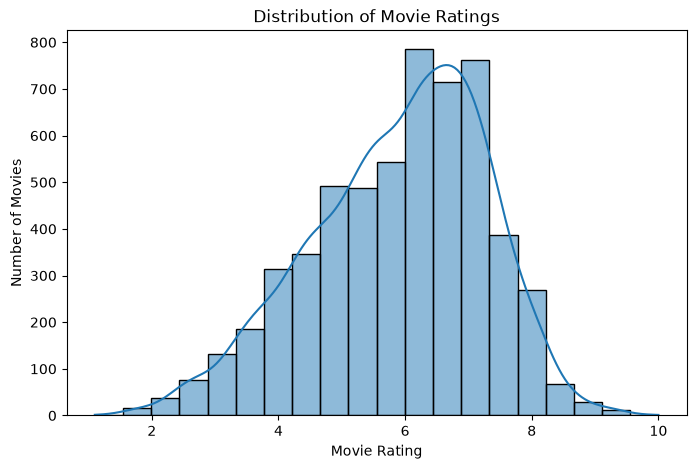

In [12]:
# Distribution of movie ratings
plt.figure(figsize=(8, 5))

sns.histplot(df["Rating"], bins=20, kde=True)

plt.title("Distribution of Movie Ratings")
plt.xlabel("Movie Rating")
plt.ylabel("Number of Movies")
plt.show()

In [13]:
# Top-rated movies
if "Movie_Name" in df.columns:
    top_movies = df.nlargest(10, "Rating")

    display(top_movies[
        ["Movie_Name", "Rating"]
    ])

,Movie_Name,Rating
3146,Love Qubool Hai,10.0
2027,Half Songs,9.7
1897,Gho Gho Rani,9.4
2574,June,9.4
5165,The Reluctant Crime,9.4
536,Ashok Vatika,9.3
692,Baikunth,9.3
1919,God of gods,9.3
3149,Love Sorries,9.3
4321,Refl3ct,9.3


,mean,count
Genre,,
Documentary,7.608333,48
History,6.905051,99
Biography,6.737391,115
Sport,6.515000,40
Family,6.323317,416
Musical,6.246845,412
Animation,6.072500,40
Music,6.071698,53
Drama,6.056744,3796


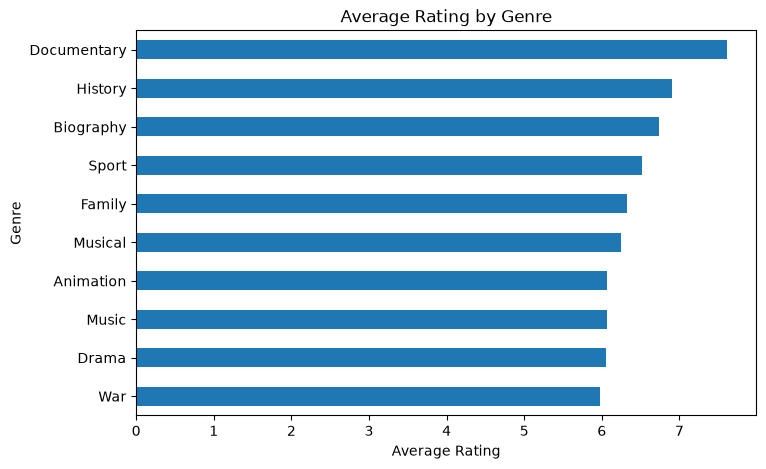

In [14]:
# Average rating by genre
if "Genre" in df.columns:
    genre_df = df[["Genre", "Rating"]].dropna().copy()

    genre_df["Genre"] = genre_df["Genre"].astype(str)

    genre_df = genre_df[
        genre_df["Genre"].str.strip().ne("")
    ]

    # Some movies have multiple genres
    genre_df["Genre"] = genre_df["Genre"].str.split(",")
    genre_df = genre_df.explode("Genre")

    genre_df["Genre"] = genre_df["Genre"].str.strip()

    genre_ratings = (
        genre_df.groupby("Genre")["Rating"]
        .agg(["mean", "count"])
        .query("count >= 10")
        .sort_values("mean", ascending=False)
        .head(10)
    )

    display(genre_ratings)

    genre_ratings["mean"].sort_values().plot(
        kind="barh", figsize=(8, 5)
    )

    plt.title("Average Rating by Genre")
    plt.xlabel("Average Rating")
    plt.show()

# Prepare features for machine learning

In [15]:
# Use available feature columns only
possible_features = [
    "Year",
    "Duration",
    "Votes",
    "Genre",
    "Director",
    "Actor_1",
    "Actor_2",
    "Actor_3"
]

feature_columns = [
    col for col in possible_features if col in df.columns
]

if not feature_columns:
    raise ValueError(
        "No expected feature columns found. "
        "Check the column names printed in Step 4."
    )

X = df[feature_columns].copy()
y = df["Rating"].copy()

# Treat text-like features as categorical
categorical_columns = X.select_dtypes(
    include=["object", "category", "string"]
).columns.tolist()

numeric_columns = X.select_dtypes(
    include=np.number
).columns.tolist()

print("Features:", feature_columns)
print("Numeric features:", numeric_columns)
print("Categorical features:", categorical_columns)
print("Total records:", len(X))

Features: ['Year', 'Duration', 'Votes', 'Genre', 'Director', 'Actor_1', 'Actor_2', 'Actor_3']
Numeric features: ['Year', 'Duration', 'Votes']
Categorical features: ['Genre', 'Director', 'Actor_1', 'Actor_2', 'Actor_3']
Total records: 5659


# Split the dataset into training and testing data

In [16]:
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42
)

print("Training records:", len(X_train))
print("Testing records:", len(X_test))

Training records: 4527
Testing records: 1132


# Handle missing values and encode categorical data

In [17]:
numeric_transformer = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="median"))
])

categorical_transformer = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("encoder", OneHotEncoder(
        handle_unknown="ignore",
        min_frequency=10,
        max_categories=50
    ))
])

preprocessor = ColumnTransformer(
    transformers=[
        ("num", numeric_transformer, numeric_columns),
        ("cat", categorical_transformer, categorical_columns)
    ],
    remainder="drop"
)

print("Preprocessing pipeline created successfully.")

Preprocessing pipeline created successfully.


# Train the machine learning model

In [18]:
model = Pipeline(steps=[
    ("preprocessor", preprocessor),
    ("regressor", RandomForestRegressor(
        n_estimators=100,
        random_state=42,
        n_jobs=-1,
        min_samples_leaf=2
    ))
])

model.fit(X_train, y_train)

print("Model training completed successfully!")

Model training completed successfully!


# Evaluate the model

In [19]:
y_pred = model.predict(X_test)

mae = mean_absolute_error(y_test, y_pred)
rmse = np.sqrt(mean_squared_error(y_test, y_pred))
r2 = r2_score(y_test, y_pred)

print(f"Mean Absolute Error (MAE): {mae:.3f}")
print(f"Root Mean Squared Error (RMSE): {rmse:.3f}")
print(f"R-squared (R²): {r2:.3f}")

Mean Absolute Error (MAE): 0.860
Root Mean Squared Error (RMSE): 1.152
R-squared (R²): 0.283


# Compare actual ratings with predicted ratings

In [20]:
results = pd.DataFrame({
    "Actual_Rating": y_test.values,
    "Predicted_Rating": y_pred
})

results["Predicted_Rating"] = results[
    "Predicted_Rating"
].round(2)

display(results.head(15))

,Actual_Rating,Predicted_Rating
0,6.0,4.92
1,2.4,6.41
2,3.8,5.07
3,3.8,4.16
4,7.2,4.69
5,6.3,5.79
6,8.6,4.95
7,3.9,4.64
8,6.6,5.04
9,6.6,6.76


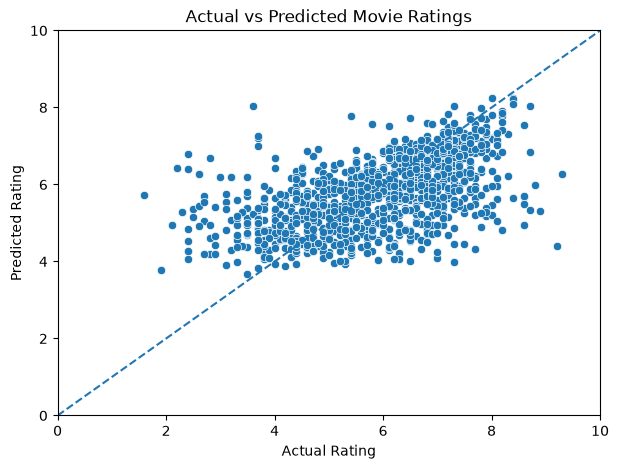

In [21]:
plt.figure(figsize=(7, 5))

sns.scatterplot(
    x=results["Actual_Rating"],
    y=results["Predicted_Rating"]
)

plt.plot([0, 10], [0, 10], linestyle="--")

plt.xlim(0, 10)
plt.ylim(0, 10)

plt.xlabel("Actual Rating")
plt.ylabel("Predicted Rating")
plt.title("Actual vs Predicted Movie Ratings")

plt.show()

# Predict a new movie rating

In [28]:
new_movie = pd.DataFrame([{
    col: np.nan for col in feature_columns
}])

# Set example values for the columns that exist
example_values = {
    "Year": 2024,
    "Duration": 120,
    "Votes": 1000,
    "Genre": "Comedy",
    "Director": "Unknown",
    "Actor_1": "Unknown",
    "Actor_2": "Unknown",
    "Actor_3": "Unknown"
}

# Create the DataFrame with correct values and data types
new_movie = pd.DataFrame([
    {
        col: example_values.get(col, np.nan)
        for col in feature_columns
    }
])

# Predict rating
predicted_rating = model.predict(new_movie)[0]

print(f"Predicted movie rating: {predicted_rating:.2f}/10")

Predicted movie rating: 5.24/10


# Save the trained model

In [23]:
joblib.dump(model, "movie_rating_model.pkl")

print("Model saved as movie_rating_model.pkl")

Model saved as movie_rating_model.pkl


In [24]:
loaded_model = joblib.load("movie_rating_model.pkl")

sample_prediction = loaded_model.predict(X_test.iloc[[0]])

print("Actual rating:", y_test.iloc[0])
print("Predicted rating:", round(sample_prediction[0], 2))

Actual rating: 6.0
Predicted rating: 4.92


# Save results

In [25]:
results.to_csv("movie_rating_predictions.csv", index=False)

print("Prediction results saved successfully.")

Prediction results saved successfully.
